In [1]:
import numpy as np
from sympy import *
import matplotlib.pyplot as plt
from math import factorial

<lambdifygenerated-1>:2: RuntimeWarning: divide by zero encountered in log
  return log(x + 1)*sin(x)


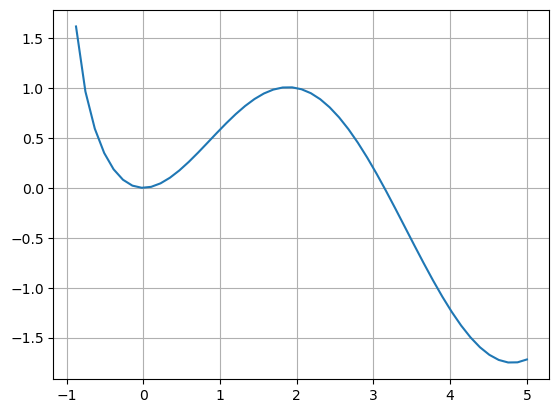

In [2]:
x = symbols('x')
f = sin(x)*log(1+x)

f_ = lambdify(x, f)
x_ = np.linspace(-1, 5)
plt.plot(x_, f_(x_))
plt.grid()

In [3]:
a = 2

f_approx = f.subs({x : a}) + (diff(f).subs({x : a})*(x - a)**1)/factorial(1) + (diff(diff(f)).subs({x : a})*(x - a)**2)/factorial(2) + (diff(diff(diff(f))).subs({x : a})*(x - a)**3)/factorial(3)
f_approx

(x - 2)**3*(-25*sin(2)/27 - cos(2)/3 - log(3)*cos(2))/6 + (x - 2)**2*(-log(3)*sin(2) + 2*cos(2)/3 - sin(2)/9)/2 + (x - 2)*(log(3)*cos(2) + sin(2)/3) + log(3)*sin(2)

<lambdifygenerated-1>:2: RuntimeWarning: divide by zero encountered in log
  return log(x + 1)*sin(x)


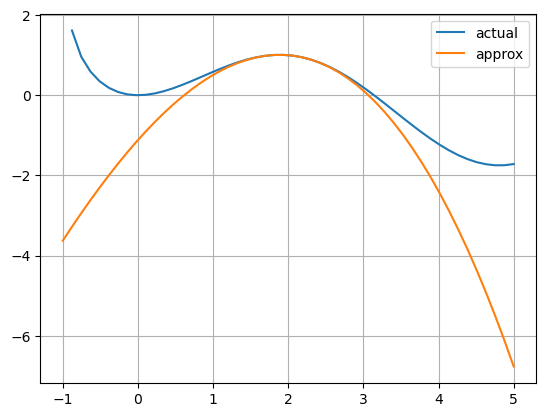

In [4]:
f_approx_ = lambdify(x, f_approx)
x_ = np.linspace(-1, 5)
plt.plot(x_, f_(x_), label='actual')
plt.plot(x_, f_approx_(x_), label='approx')
plt.grid()
plt.legend()

In [11]:
def get_derivative(f, n):
    for i in range(n):
        f = diff(f)
    return f

def get_f_approx(f, a, n):
    x = symbols('x')
    f_approx = f.subs({x : a})
    for i in range(1, n):
        f_approx += (get_derivative(f, i).subs({x: a})*(x-a)**i)/factorial(i)
    return f_approx.n(2)

x = symbols('x')
# f = sin(x)*exp(cos(x**2))
# get_f_approx(f, 0, 10)





f = sin(0.5*x**2 + 32)*exp(-0.007*x**2)


# np.sin(0.5*x**2 + 32)*np.exp(-0.007*x**2)

(-1.5, 1.5)

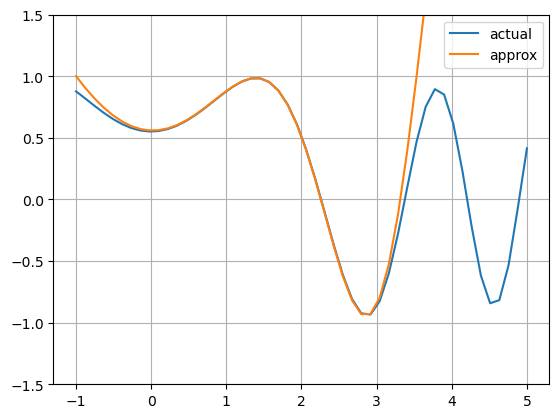

In [23]:
f_ = lambdify(x, f)
f_approx_ = lambdify(x, get_f_approx(f, 1, 100))
x_ = np.linspace(-1, 5)
plt.plot(x_, f_(x_), label='actual')
plt.plot(x_, f_approx_(x_), label='approx')
plt.grid()
plt.legend()
plt.ylim([-1.5, 1.5])

In [ ]:
x = np.linspace(-2, 5, 1000)
population_fun = np.sin(0.5*x**2 + 32)*np.exp(-0.007*x**2)



N = 1000
sigma = 0.1
x_data = np.random.uniform(-2, 5, size=N)
y_data = np.sin(0.5*x_data**2 + 32)*np.exp(-0.007*x_data**2) + np.random.normal(scale=sigma, size=N)

df_pop = pd.DataFrame(data=np.column_stack((x_data, y_data)), columns=["X", "y"])
plt.scatter(df_pop["X"], df_pop["y"])
plt.plot(x, population_fun, "r")